# Computer Vision — Lab Assignment 03
**Fine-tuning CNN architectures with data augmentation (Cats vs Dogs)**

**Student:** Sarim Azhar | **Roll No:** 247076  
**Submitted to:** Ayesha Sahar  
Air University, Kharian Campus — BSCS, Fall 2026

**Selected architectures:** VGG16, ResNet50, MobileNetV2, EfficientNetB0

> Run on a GPU: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 1. Dataset
**Microsoft Cats vs Dogs** (Kaggle PetImages): about 25,000 colour images in 2 balanced classes (Cat, Dog) of varying sizes.
Corrupt files are removed, and the rest is split with stratification into **80% train / 10% validation / 10% test**.
All images are resized to 224×224, the input size all four models were pre-trained on (ImageNet).

## 2. Choice of variants
| Architecture | Variant | Reason for this dataset |
|---|---|---|
| VGG | **VGG16** | Binary task with ~20k training images; VGG19 adds 3 more conv layers and parameters with no real gain here. |
| ResNet | **ResNet50** | Deep enough to have strong features via residual connections; ResNet101/152 would be overkill and slower for 2 classes. |
| MobileNet | **MobileNetV2** (α=1.0) | Lightweight (~2.3M base params); inverted residuals; native 224×224 input. |
| EfficientNet | **EfficientNetB0** | B0 is the baseline scaled for 224×224 input; larger B-variants expect higher resolutions (240–600 px) that this dataset does not need. |

In [1]:
import os, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
HEAD_EPOCHS = 5      # phase 1: train only the new classifier head
FT_EPOCHS = 5        # phase 2: fine-tune top layers of the base model
SUBSET = None        # e.g. 0.3 to train on 30% of the training set if lab time is short
CLASS_NAMES = ["Cat", "Dog"]

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Download and clean the data

In [2]:
!wget -q -O cats_dogs.zip https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
!unzip -q -o cats_dogs.zip
DATA_DIR = "PetImages"
print(os.listdir(DATA_DIR))

['Dog', 'Cat']


In [3]:
# Remove files that are empty, not JPEG (no JFIF header) or cannot be decoded
removed = 0
for cls in CLASS_NAMES:
    folder = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(folder):
        fpath = os.path.join(folder, fname)
        try:
            with open(fpath, "rb") as f:
                ok = b"JFIF" in f.peek(10)
            if ok:
                tf.io.decode_image(tf.io.read_file(fpath), channels=3, expand_animations=False)
        except Exception:
            ok = False
        if not ok:
            os.remove(fpath)
            removed += 1
print("Removed corrupt files:", removed)
for cls in CLASS_NAMES:
    print(cls, len(os.listdir(os.path.join(DATA_DIR, cls))))

Removed corrupt files: 1592
Cat 11741
Dog 11669


## 4. Train / validation / test split

In [4]:
paths, labels = [], []
for label, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_DIR, cls)
    for fname in sorted(os.listdir(folder)):
        paths.append(os.path.join(folder, fname))
        labels.append(label)
paths, labels = np.array(paths), np.array(labels)

X_train, X_temp, y_train, y_temp = train_test_split(paths, labels, test_size=0.2, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
if SUBSET:
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=SUBSET, stratify=y_train, random_state=SEED)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)          # float32 in [0, 255]
    return img, tf.cast(label, tf.float32)

def make_raw_ds(x, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)

train_raw = make_raw_ds(X_train, y_train, shuffle=True)
val_raw = make_raw_ds(X_val, y_val)
test_raw = make_raw_ds(X_test, y_test)

Train: 18728 | Val: 2341 | Test: 2341


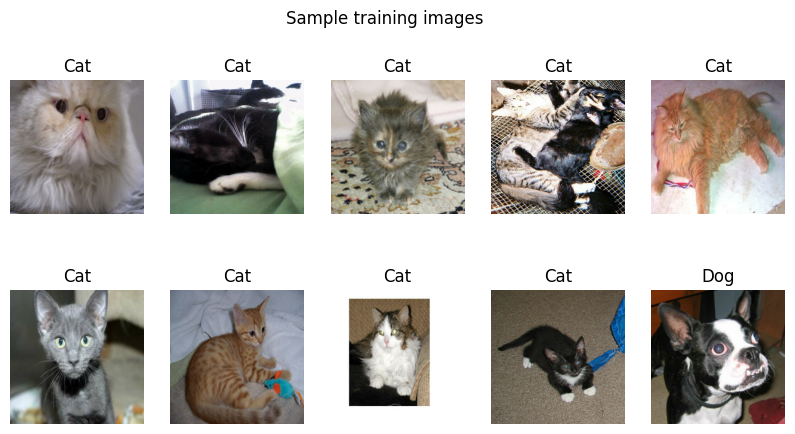

In [5]:
images, lbls = next(iter(train_raw))
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(lbls[i])])
    plt.axis("off")
plt.suptitle("Sample training images")
plt.show()

## 5. Image data augmentation
Augmentation is applied **on the GPU inside each model** and is active only during training (not for validation or testing):
- **RandomFlip (horizontal):** a mirrored cat is still a cat.
- **RandomRotation (±10%, about ±36°):** handles tilted camera angles.
- **RandomZoom (±10%)** and **RandomTranslation (±10%):** the animal appears at different scales and positions.

Only geometric transforms are used, so they stay valid after each model's own input preprocessing (which shifts pixel values to model-specific ranges).

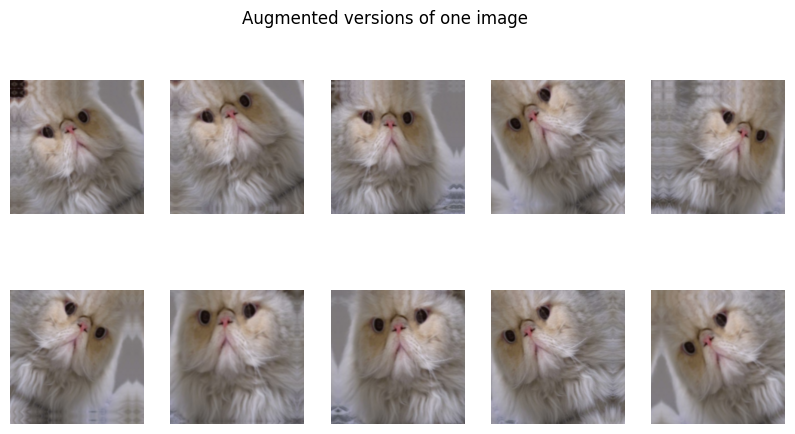

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
], name="augmentation")

img = images[0:1]
plt.figure(figsize=(10, 5))
for i in range(10):
    aug = data_augmentation(img, training=True)
    plt.subplot(2, 5, i + 1)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.axis("off")
plt.suptitle("Augmented versions of one image")
plt.show()

## 6. Model building and fine-tuning strategy
Each model uses its ImageNet weights with the original classifier removed (`include_top=False`), followed by
`GlobalAveragePooling2D → Dropout(0.3) → Dense(1, sigmoid)`.

Training is done in two phases:
1. **Feature extraction:** the base is frozen and only the new head is trained (Adam, lr = 1e-3).
2. **Fine-tuning:** the top layers of the base are unfrozen and trained with a much smaller learning rate (Adam, lr = 1e-5) so the pre-trained weights adapt without being destroyed. BatchNormalization layers stay frozen (the base runs with `training=False`) so their ImageNet statistics are not disturbed by small batches.

| Model | Layers unfrozen in phase 2 |
|---|---|
| VGG16 | last conv block (block5: 3 conv + pool = 4 layers) |
| ResNet50 | last 30 layers (≈ conv5 stage) |
| MobileNetV2 | last 30 layers (last ~3 inverted-residual blocks) |
| EfficientNetB0 | last 20 layers (block 7 + top conv) |

EarlyStopping (patience 2, restores best weights) and ReduceLROnPlateau guard against overfitting.

In [7]:
MODELS = {
    #  name           : (constructor,                        preprocess_input,                          layers to unfreeze)
    "VGG16":          (keras.applications.VGG16,          keras.applications.vgg16.preprocess_input,        4),
    "ResNet50":       (keras.applications.ResNet50,       keras.applications.resnet50.preprocess_input,     30),
    "MobileNetV2":    (keras.applications.MobileNetV2,    keras.applications.mobilenet_v2.preprocess_input, 30),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input, 20),
}

def prepare(ds, preprocess):
    return ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

def get_metrics():
    return ["accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

def build_model(name):
    constructor = MODELS[name][0]
    base = constructor(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name=name), base

def train_model(name):
    _, preprocess, n_unfreeze = MODELS[name]
    train_ds, val_ds = prepare(train_raw, preprocess), prepare(val_raw, preprocess)
    model, base = build_model(name)

    # Phase 1: feature extraction
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=get_metrics())
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    start = time.time()
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=[early])

    # Phase 2: fine-tuning
    base.trainable = True
    for layer in base.layers[:-n_unfreeze]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy", metrics=get_metrics())
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=1, min_lr=1e-7)
    phase1_epochs = len(h1.epoch)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=phase1_epochs + FT_EPOCHS,
                   initial_epoch=phase1_epochs, callbacks=[early, reduce_lr])
    train_time = time.time() - start

    history = {k: h1.history[k] + h2.history.get(k, []) for k in h1.history}
    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
    print(f"{name}: total params = {model.count_params():,} | trainable in fine-tuning = {trainable:,}")
    return model, history, phase1_epochs, train_time

def evaluate_model(name, model):
    test_ds = prepare(test_raw, MODELS[name][1])
    y_true, y_prob = [], []
    start = time.time()
    for x, y in test_ds:
        y_prob.append(model.predict_on_batch(x).ravel())
        y_true.append(y.numpy().ravel())
    infer_time = time.time() - start
    y_true, y_prob = np.concatenate(y_true).astype(int), np.concatenate(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "y_true": y_true, "y_prob": y_prob, "y_pred": y_pred,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "ms / image": 1000 * infer_time / len(y_true),
    }

## 7. Evaluation metrics
- **Accuracy:** share of test images classified correctly (meaningful here because the classes are balanced).
- **Precision (Dog):** of the images predicted *Dog*, how many really are dogs.
- **Recall (Dog):** of the real dogs, how many were found.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** how well the predicted probabilities separate the two classes, regardless of the 0.5 threshold.
- **Confusion matrix:** shows which class is confused with which.
- **Parameters, training time and inference time (ms/image):** compare model cost against accuracy.

## 8. Train and evaluate all four models

In [8]:
results, histories, ft_start, trained = {}, {}, {}, {}

def plot_history(name):
    h, s = histories[name], ft_start[name]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, metric in enumerate(["accuracy", "loss"]):
        ax[i].plot(h[metric], label="train")
        ax[i].plot(h["val_" + metric], label="validation")
        ax[i].axvline(s - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
        ax[i].set_title(f"{name} — {metric}")
        ax[i].set_xlabel("epoch")
        ax[i].legend()
    plt.show()

def plot_confusion(name):
    r = results[name]
    cm = confusion_matrix(r["y_true"], r["y_pred"])
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"{name} — confusion matrix")
    plt.show()
    print(classification_report(r["y_true"], r["y_pred"], target_names=CLASS_NAMES, digits=4))

def run(name):
    print("=" * 70, f"\n{name}\n" + "=" * 70)
    model, history, s, t = train_model(name)
    res = evaluate_model(name, model)
    res["Params (M)"] = model.count_params() / 1e6
    res["Train time (min)"] = t / 60
    results[name], histories[name], ft_start[name], trained[name] = res, history, s, model
    plot_history(name)
    plot_confusion(name)

### 8.1 VGG16

In [ ]:
run("VGG16")

VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 122s 189ms/step - accuracy: 0.8681 - auc: 0.9353 - loss: 0.4988 - precision: 0.8690 - recall: 0.8658 - val_accuracy: 0.9739 - val_auc: 0.9972 - val_loss: 0.0662 - val_precision: 0.9718 - val_recall: 0.9760
Epoch 2/5
586/586 ━━━━━━━━━━━━━━━━━━━━ 106s 181ms/step - accuracy: 0.9486 - auc: 0.9879 - loss: 0.1464 - precision: 0.9507 - recall: 0.9460 - val_accuracy: 0.9821 - val_auc: 0.9978 - val_loss: 0.0522 - val_precision: 0.9812 - val_recall: 0.9829
Epoch 3/5
481/586 ━━━━━━━━━━━━━━━━━━━━ 16s 162ms/step - accuracy: 0.9545 - auc: 0.9906 - loss: 0.1271 - precision: 0.9534 - recall: 0.9550

### 8.2 ResNet50

In [ ]:
run("ResNet50")

### 8.3 MobileNetV2

In [ ]:
run("MobileNetV2")

### 8.4 EfficientNetB0

In [ ]:
run("EfficientNetB0")

## 9. Comparative analysis

In [ ]:
cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Params (M)", "Train time (min)", "ms / image"]
summary = pd.DataFrame({m: {c: results[m][c] for c in cols} for m in results}).T
summary = summary.sort_values("F1-score", ascending=False)
summary.style.format({c: "{:.4f}" for c in cols[:5]} | {c: "{:.2f}" for c in cols[5:]}) \
       .highlight_max(subset=cols[:5], color="lightgreen") \
       .highlight_min(subset=cols[5:], color="lightgreen")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

summary[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_ylim(max(0, summary[["Accuracy", "Precision", "Recall", "F1-score"]].values.min() - 0.03), 1.0)
ax[0].set_title("Test metrics"); ax[0].legend(loc="lower right", fontsize=8)

for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_prob"])
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={r['ROC-AUC']:.4f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curves")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(fontsize=8)

for name in results:
    ax[2].plot(histories[name]["val_accuracy"], marker="o", label=name)
ax[2].set_title("Validation accuracy per epoch"); ax[2].set_xlabel("epoch"); ax[2].legend(fontsize=8)
plt.show()

plt.figure(figsize=(7, 4.5))
for name in summary.index:
    plt.scatter(summary.loc[name, "Params (M)"], summary.loc[name, "Accuracy"], s=120)
    plt.annotate(name, (summary.loc[name, "Params (M)"], summary.loc[name, "Accuracy"]),
                 textcoords="offset points", xytext=(6, 6))
plt.xlabel("Parameters (millions)"); plt.ylabel("Test accuracy"); plt.title("Accuracy vs model size")
plt.grid(alpha=0.3); plt.show()

In [ ]:
best = summary["F1-score"].idxmax()
fastest = summary["ms / image"].idxmin()
smallest = summary["Params (M)"].idxmin()
efficiency = (summary["Accuracy"] / summary["Params (M)"]).idxmax()

print(f"Best overall (F1-score): {best}  -> accuracy {summary.loc[best, 'Accuracy']:.4f}, F1 {summary.loc[best, 'F1-score']:.4f}")
print(f"Fastest inference:       {fastest} ({summary.loc[fastest, 'ms / image']:.2f} ms/image)")
print(f"Smallest model:          {smallest} ({summary.loc[smallest, 'Params (M)']:.2f} M params)")
print(f"Best accuracy per param: {efficiency}")
print()
for name in summary.index:
    h = histories[name]
    gap = h["accuracy"][-1] - h["val_accuracy"][-1]
    gain = max(h["val_accuracy"][ft_start[name]:] or [np.nan]) - max(h["val_accuracy"][:ft_start[name]])
    print(f"{name:15s} train-val accuracy gap: {gap:+.4f} | val accuracy gain from fine-tuning: {gain:+.4f}")

### Sample predictions from the best model

In [ ]:
model = trained[best]
x_batch, y_batch = next(iter(test_raw))
probs = model.predict(MODELS[best][1](tf.identity(x_batch)), verbose=0).ravel()
plt.figure(figsize=(14, 6))
for i in range(12):
    plt.subplot(2, 6, i + 1)
    plt.imshow(x_batch[i].numpy().astype("uint8"))
    pred, true = int(probs[i] >= 0.5), int(y_batch[i])
    plt.title(f"P: {CLASS_NAMES[pred]} ({max(probs[i], 1 - probs[i]):.2f})\nT: {CLASS_NAMES[true]}",
              color="green" if pred == true else "red", fontsize=9)
    plt.axis("off")
plt.suptitle(f"{best} predictions on test images"); plt.show()

## 10. How to read the results
- **Accuracy vs cost:** VGG16 has the most parameters (~14.7M in the base, almost all in conv layers) and the slowest inference, so its accuracy should be weighed against its size. MobileNetV2 and EfficientNetB0 are designed to give high accuracy for a fraction of the computation.
- **Fine-tuning effect:** the "gain from fine-tuning" line shows how much unfreezing the top layers improved validation accuracy over the frozen-base phase.
- **Overfitting:** a large positive train–validation gap means the model is memorising the training set; augmentation, dropout and early stopping are meant to keep it small.
- **Errors:** the confusion matrices and red titles in the sample grid show which class each model confuses more often; typical errors are low-light images, partial views and images with both animals or people.